# Análisis exploratorio de datos : Dengue

## Objetivo

Explorar el dataset consolidado de dengue mediante visualizaciones estadísticas para comprender la distribución de los datos, identificar posibles valores atípicos, analizar relaciones entre variables y reconocer patrones relevantes para la comprensión del comportamiento de la enfermedad.

Se utilizarán histogramas, boxplots, matrices de correlación y gráficos adicionales con Matplotlib y Seaborn.

El análisis buscará traducir los resultados estadísticos en hallazgos útiles para la interpretación epidemiológica y la toma de decisiones.

##  1. Carga de datos y bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_parquet("../datos/procesados/dengue_consolidado.parquet")

# EDAD viene en distintas unidades segun UNI_MED (1 = anos, 2 = meses, 3 = dias, 4 = horas):
# se lleva todo a anos para que las graficas de edad sean comparables.
divisor_unidad = {1: 1, 2: 12, 3: 365, 4: 8760}
df["EDAD_ANIOS"] = pd.to_numeric(df["EDAD"]) / pd.to_numeric(df["UNI_MED"]).map(divisor_unidad)

# PAC_HOS viene codificada 1 = Si y 2 = No: se crea una bandera 0/1 facil de leer
df["HOSPITALIZADO"] = (pd.to_numeric(df["PAC_HOS"]) == 1).astype(int)

print("Dimensiones del dataset:")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

print("\nTipo de dato de cada columna:")
display(df.dtypes.to_frame(name="Tipo de dato"))

Dimensiones del dataset:
Filas: 581071
Columnas: 22

Tipo de dato de cada columna:


,Tipo de dato
SEMANA,int64
ANO,int64
EDAD,int64
UNI_MED,int64
SEXO,str
COD_DPTO_O,int64
COD_MUN_O,int64
AREA,int64
TIP_SS,str
PER_ETN,int64


## 2. Reconocimiento de los datos GRAFICOS 

A continuación, se presentan los gráficos generados a partir del dataset consolidado de dengue, con el objetivo de explorar la distribución de las variables y detectar posibles valores atípicos.

### 1. Histogramas de variables numéricas

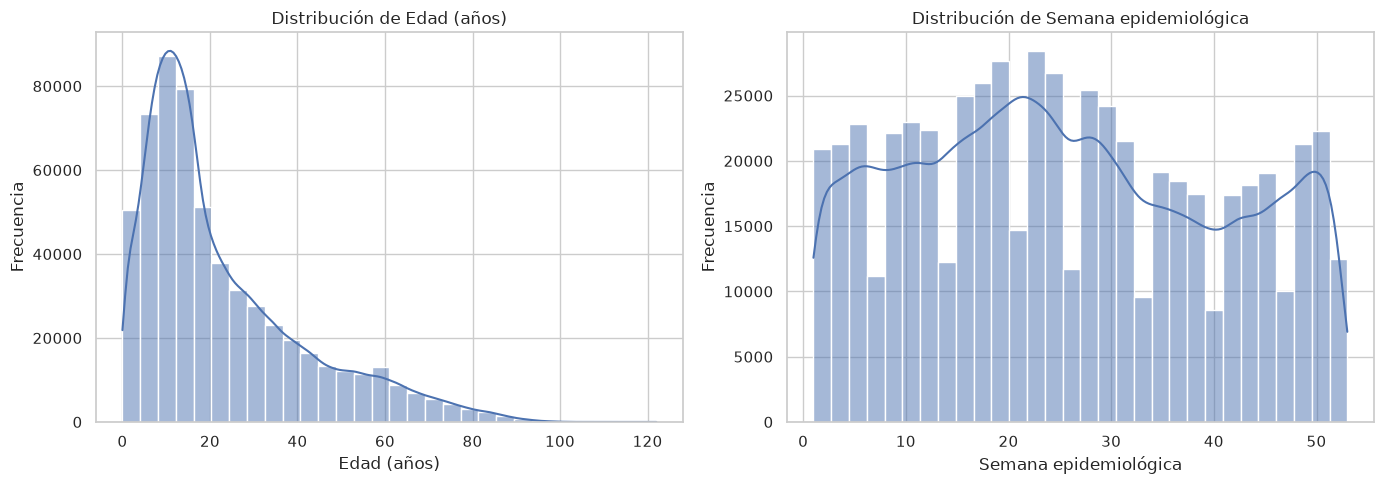

In [2]:
columnas_numericas = ["EDAD_ANIOS", "SEMANA"]

nombres = {"EDAD_ANIOS": "Edad (años)", "SEMANA": "Semana epidemiológica"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, columna in zip(axes, columnas_numericas):
    sns.histplot(data=df, x=columna, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribución de {nombres[columna]}")
    ax.set_xlabel(nombres[columna])
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

No se incluyeron todos los campos numéricos porque algunas columnas, como COD_DPTO_O y COD_MUN_O, representan códigos de identificación y no cantidades numéricas que tenga sentido distribuir mediante histogramas. Para cumplir completamente el objetivo del análisis exploratorio, se deben evaluar las demás variables numéricas y seleccionar aquellas cuya distribución aporte información relevante.
### Insight:
La variable de edad revela una marcada hiperconcentración de casos en la población infantil, situando su punto más crítico entre los 5 y 12 años, lo que exige dirigir la asignación presupuestal y las campañas preventivas directamente hacia el entorno escolar e instituciones pediátricas. En cuanto a la estacionalidad, el comportamiento bimodal muestra dos picos previsibles de alta demanda: el principal entre las semanas 20 y 25 (mayo-junio), con cerca de 14,700 registros en la semana más alta sumando los cuatro años, y un repunte secundario entre las semanas 48 y 52 (noviembre-diciembre). En consecuencia, la gestión operativa debe programar la compra de insumos y la rotación de personal asistencial antes de la semana 18 para evitar la saturación del servicio durante las ventanas de mayor afluencia.

### 2. Boxplot de la edad

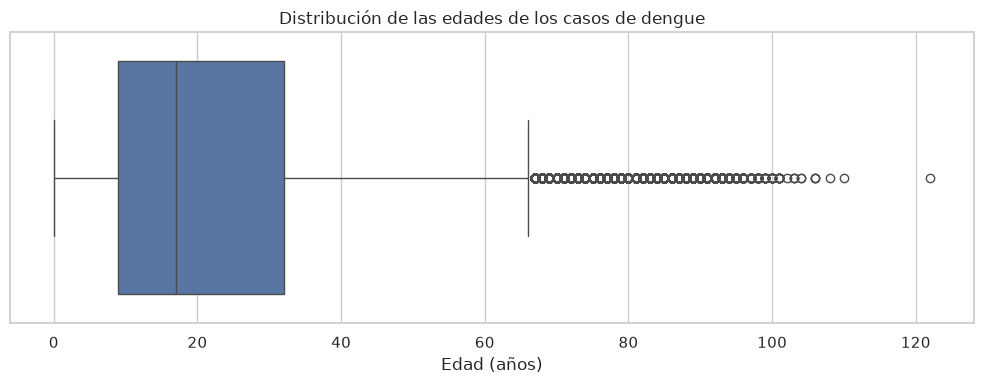

Cantidad de edades válidas: 581071
Edad mínima: 0.00045662100456621003
Edad máxima: 122.0


In [3]:
col_edad = "EDAD_ANIOS"   # edad ya convertida a años


if col_edad is not None:
    edades = pd.to_numeric(df[col_edad], errors="coerce").dropna()

    plt.figure(figsize=(10, 4))
    sns.boxplot(x=edades)
    plt.title("Distribución de las edades de los casos de dengue")
    plt.xlabel("Edad (años)")
    plt.tight_layout()
    plt.show()

    print("Cantidad de edades válidas:", len(edades))
    print("Edad mínima:", edades.min())
    print("Edad máxima:", edades.max())
else:
    print("No se detectó automáticamente la columna de edad.")
    print("Revisa las columnas impresas en la primera celda.")

La gran mayoría de las columnas restantes (SEXO, TIP_SS, Departamento_ocurrencia, PAC_HOS) representan categorías, etiquetas o valores binarios. Aplicar un boxplot a estas variables generaría líneas planas o bloques rígidos sin cuartiles ni variabilidad interpretable.
### Insight:
La distribución de edades evidencia una alta concentración de casos de dengue en la población infantojuvenil, situando la mediana en aproximadamente 17 años y comprimiendo el 50% central de los registros entre los 10 y 32 años. La dispersión superior clasifica a los adultos mayores de 65 años como valores atípicos (*outliers*), detectando incluso valores extremos superiores a los 100 y 120 años que sugieren posibles errores de digitación en el sistema. En consecuencia, las intervenciones de salud pública deben priorizar los entornos escolares y juveniles, complementándose con una auditoría de calidad de datos para validar las edades extremas reportadas.

### 3. Heatmap de correlación de Pearson y Spearman

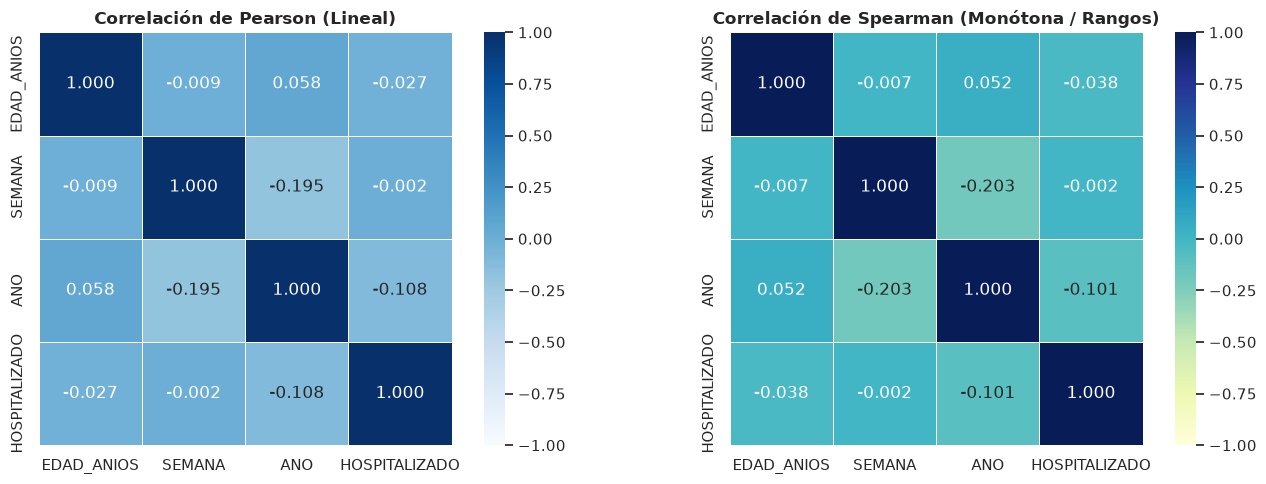

In [4]:


# 1. Selección de variables cuantitativas/métricas numéricas reales
vars_correlacion = ["EDAD_ANIOS", "SEMANA", "ANO", "HOSPITALIZADO"]

# 2. Cálculo de matrices de correlación
matriz_pearson = df[vars_correlacion].apply(pd.to_numeric).corr(method="pearson")
matriz_spearman = df[vars_correlacion].apply(pd.to_numeric).corr(method="spearman")

# 3. Visualización gráfica comparativa con Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Pearson
sns.heatmap(
    matriz_pearson,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    ax=axes[0],
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=0.5,
)
axes[0].set_title(
    "Correlación de Pearson (Lineal)", fontsize=12, fontweight="bold"
)

# Heatmap Spearman
sns.heatmap(
    matriz_spearman,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    ax=axes[1],
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=0.5,
)
axes[1].set_title(
    "Correlación de Spearman (Monótona / Rangos)",
    fontsize=12,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

### Insight:
Las matrices de Pearson y Spearman muestran coeficientes casi nulos entre la hospitalización, la edad (−0.03 y −0.04) y la semana epidemiológica (≈ 0), y una relación débil con el año (−0.11): la hospitalización registrada bajó en los años más recientes. Que la correlación sea casi cero **no significa que la edad no importe**: estos coeficientes solo miden relaciones lineales o monótonas, y la gráfica 6 muestra que la hospitalización tiene forma de U según la edad (más alta en bebés y adultos mayores). Para el negocio, ninguna variable aislada basta para anticipar la hospitalización; por eso los modelos de la Fase C combinan varias y tratan la edad por grupos.

### 4. Evolución semanal por año

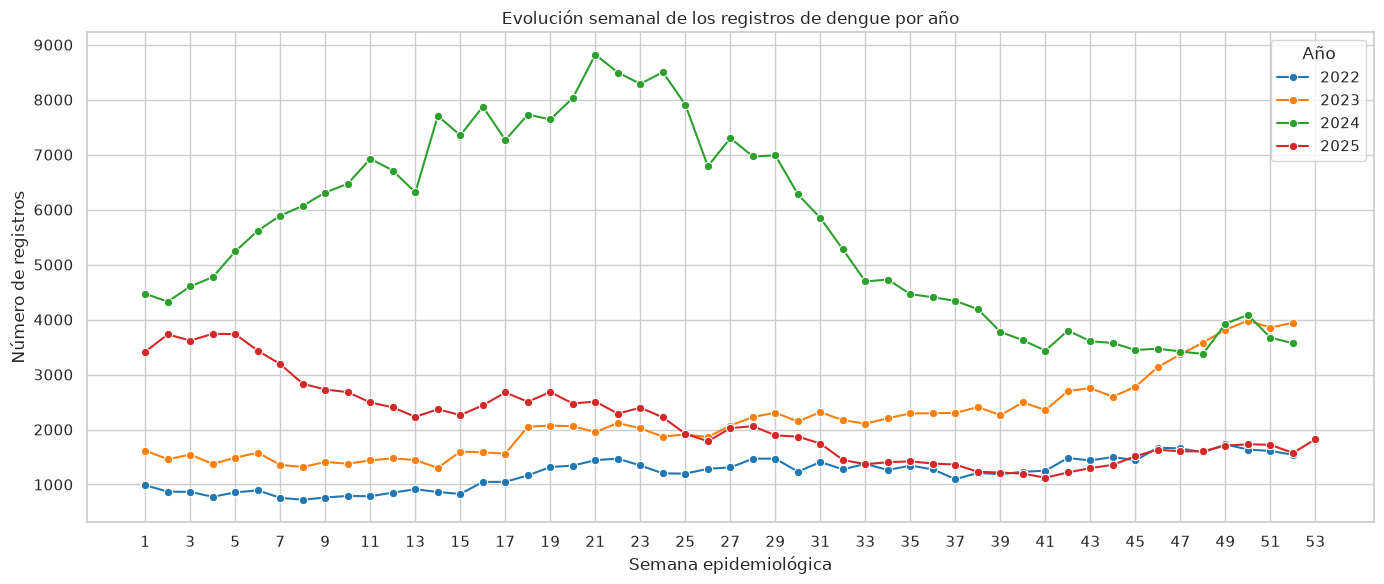

In [5]:
evolucion = df.groupby(["ANO", "SEMANA"]).size().reset_index(name="CASOS")

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=evolucion,
    x="SEMANA",
    y="CASOS",
    hue="ANO",
    palette="tab10",
    marker="o"
)

plt.title("Evolución semanal de los registros de dengue por año")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Número de registros")
plt.xticks(range(1, 54, 2))
plt.legend(title="Año")
plt.tight_layout()
plt.show()

### Insight:
La evolución interanual evidencia que el riesgo epidemiológico varía drásticamente entre periodos, destacando el año 2024 como un brote epidémico atípico que alcanzó un pico crítico cercano a los 8,800 casos semanales entre las semanas 15 y 25, en fuerte contraste con la curva endémica baja de 2022 y la estabilización progresiva vista en 2025. Este comportamiento demuestra cómo la tendencia ascendente iniciada a finales de 2023 detonó una sobrecarga de atención en el primer semestre del año siguiente, confirmando que la asignación de presupuestos y reservas de insumos no debe basarse en promedios históricos estáticos, sino en sistemas de alerta temprana activados desde el último trimestre del año previo.

### 5.Top 10 departamentos con más registros

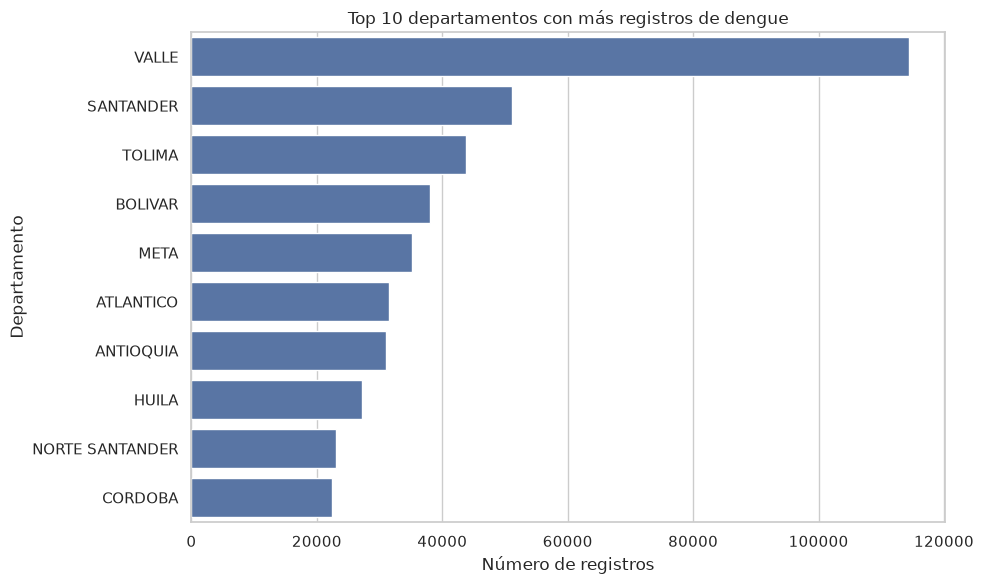

In [6]:
top10 = df["Departamento_ocurrencia"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index)

plt.title("Top 10 departamentos con más registros de dengue")
plt.xlabel("Número de registros")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

### Insight:
La distribución geográfica evidencia una extrema concentración territorial de la carga epidemiológica, encabezada de forma abrumadora por el departamento del Valle con cerca de 115,000 registros, superando por más del doble al segundo y tercer lugar (Santander y Tolima). Este comportamiento demuestra que la demanda asistencial no se distribuye homogéneamente en el territorio nacional, sino que responde a focos endémicos regionales altamente críticos que absorben la mayor parte del impacto poblacional. En consecuencia, la asignación de presupuestos, la logística de insumos médicos y las campañas de control del vector deben focalizarse con prioridad estratégica en estas regiones de alta densidad para maximizar la efectividad de la respuesta en salud pública.

###  6. Proporción de hospitalización por grupo de edad

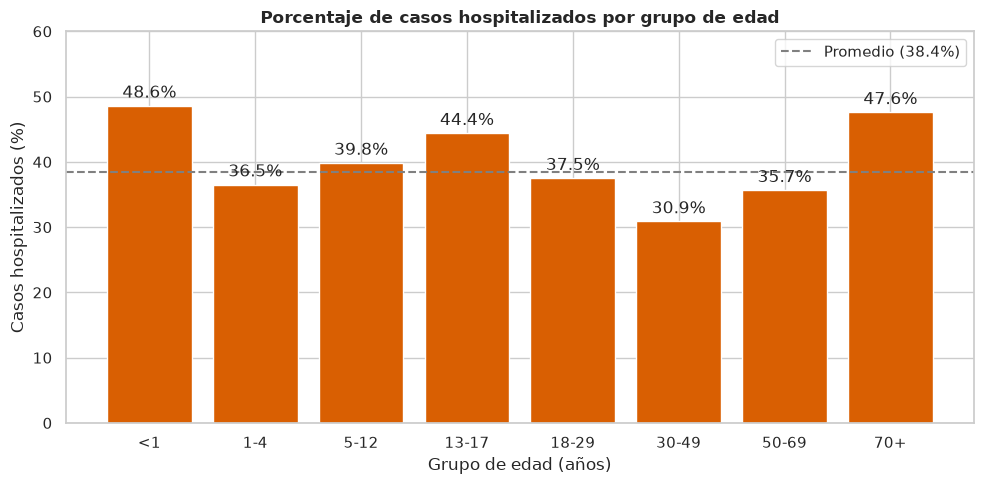

,casos,tasa_hospitalizacion
rango_edad,,
<1,8580,0.486
1-4,41869,0.365
5-12,160573,0.398
13-17,95151,0.444
18-29,112394,0.375
30-49,95566,0.309
50-69,49105,0.357
70+,17833,0.476


In [7]:
# Grupos de edad en años (mismos cortes de la Fase B), separando a los menores de 1 año
bins = [0, 1, 5, 13, 18, 30, 50, 70, 200]
labels = ["<1", "1-4", "5-12", "13-17", "18-29", "30-49", "50-69", "70+"]
df["rango_edad"] = pd.cut(df["EDAD_ANIOS"], bins=bins, labels=labels, right=False)

# Porcentaje de hospitalizados por grupo (HOSPITALIZADO: 1 = sí, 0 = no)
hosp_edad = df.groupby("rango_edad", observed=True)["HOSPITALIZADO"].mean() * 100
tasa_global = df["HOSPITALIZADO"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(hosp_edad.index.astype(str), hosp_edad.values, color="#d95f02")
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.axhline(tasa_global, ls="--", color="gray", label=f"Promedio ({tasa_global:.1f}%)")
ax.set_title("Porcentaje de casos hospitalizados por grupo de edad", fontweight="bold")
ax.set_xlabel("Grupo de edad (años)")
ax.set_ylabel("Casos hospitalizados (%)")
ax.set_ylim(0, 60)
ax.legend()
plt.tight_layout()
plt.show()

display(df.groupby("rango_edad", observed=True)["HOSPITALIZADO"].agg(casos="size", tasa_hospitalizacion="mean").round(3))

### Insight:
La hospitalización registrada tiene **forma de U** según la edad: es más alta en los menores de 1 año (48.6%) y en los mayores de 70 (47.6%), y más baja en los adultos de 30 a 49 años (30.9%), frente a un promedio de 38.4%. Los escolares de 5 a 12 años no son el grupo de mayor riesgo, pero sí el de más casos (160 mil), así que aportan el mayor número absoluto de hospitalizaciones. Para la planeación, las camas y el seguimiento de signos de alarma deben priorizar a bebés y adultos mayores, sin descuidar el volumen pediátrico en temporada alta.

*Nota:* una versión anterior de esta gráfica leía `PAC_HOS` como 1 = no hospitalizado y mostraba un 70% de hospitalización en adultos; esa cifra correspondía a los no hospitalizados y se corrigió en la Fase B.